# 03 - Docking (Phase 4b)

In the only defensible order: **the redocking gate first**. Nothing else in this
notebook runs until a protocol has reproduced a known experimental pose.

**Pass check 4a - the gate for the whole project:** top-ranked redocked pose within
**2.0 A** heavy-atom RMSD of the crystal pose, reproduced with at least two different
random seeds.

Run `02_prepare.ipynb` first. Kernel: **Python (dhfr)**.

In [1]:
import json
import sys

sys.path.insert(0, "../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dhfr_lib as D

boxes = {k: np.array(v) for k, v in json.loads((D.PREP / "boxes.json").read_text()).items()}
receptors = json.loads((D.PREP / "receptors.json").read_text())

GATE_A = 2.0
print(D.toolchain())
print("receptors:", list(receptors))

{'rdkit': '2026.09.2', 'biopython': '1.88', 'meeko': '0.8.0', 'vina': 'AutoDock Vina v1.2.7'}
receptors: ['2w9g', '1rx2', '1u72', 'af_ecoli']


## Run 1: redocking validation

Take `2W9G` (*S. aureus* DHFR crystallised with trimethoprim **and** NADPH), remove
trimethoprim, and dock the SMILES-built molecule back in.

### How the RMSD is defined

For $N$ matched heavy atoms with positions $\mathbf{r}_i$ in the docked pose and
$\mathbf{r}_i^{\,\mathrm{xtal}}$ in the crystal:

$$
\mathrm{RMSD} \;=\; \sqrt{\frac{1}{N}\sum_{i=1}^{N}\bigl\lVert \mathbf{r}_i - \mathbf{r}_i^{\,\mathrm{xtal}} \bigr\rVert^{2}}
$$

Trimethoprim is nearly symmetric in places, the two outer methoxy groups and the
amino-substituted ring can be relabelled without changing the molecule. Naive atom
matching would punish a correct pose for being "the wrong way round", so the symmetry-aware
form minimises over the automorphism group $\mathcal{A}$ of the molecular graph:

$$
\mathrm{RMSD}_{\mathrm{sym}} \;=\; \min_{\pi \in \mathcal{A}} \sqrt{\frac{1}{N}\sum_{i=1}^{N}\bigl\lVert \mathbf{r}_i - \mathbf{r}_{\pi(i)}^{\,\mathrm{xtal}} \bigr\rVert^{2}}
$$

This is what RDKit's `CalcRMS` computes. **No superposition is performed**: the pose is
compared in place, in the receptor frame, which is the whole point: we are asking whether
docking put the molecule where the crystal found it, not whether the shapes match.

That is also why Vina's own `rmsd l.b.` / `rmsd u.b.` columns are useless here. They
compare poses *with each other*, never with experiment.

**Gate:** $\mathrm{RMSD}_{\mathrm{sym}} < 2.0\ \text{Å}$ for the top-ranked pose,
reproduced across at least two seeds.

In [2]:
xtal_top = [l for l in (D.PREP / "2w9g_TOP_xtal.pdb").read_text().splitlines()
            if l.startswith(("ATOM", "HETATM"))]
rec_2w9g = D.PREP / "2w9g_receptor.pdbqt"

gate_rows = []
for form, smiles in (("protonated", D.TMP_SMILES_PROTONATED), ("neutral", D.TMP_SMILES)):
    lig = D.PREP / f"tmp_{form}.pdbqt"
    for seed in (1, 2, 3):
        res = D.run_vina(rec_2w9g, lig, boxes["2w9g"], f"redock_2w9g_{form}_s{seed}",
                         seed=seed, exhaustiveness=32)
        rmsds = D.pose_rmsds(res.out_pdbqt, xtal_top, D.TMP_SMILES)
        gate_rows.append({
            "form": form, "seed": seed,
            "top_score": res.top_score,
            "top_rmsd": round(rmsds[0], 3),
            "best_rmsd_any_mode": round(min(rmsds), 3),
            "best_mode_index": int(np.argmin(rmsds)) + 1,
            "passes": rmsds[0] < GATE_A,
        })

gate = pd.DataFrame(gate_rows)
gate

[RDKit] WARNING:[15:35:00] WARNING: More than one matching pattern found - picking one


[RDKit] WARNING:


[RDKit] WARNING:[15:35:05] WARNING: More than one matching pattern found - picking one


[RDKit] WARNING:


[RDKit] WARNING:[15:35:11] WARNING: More than one matching pattern found - picking one


[RDKit] WARNING:


... (3 outputs left out)

[RDKit] WARNING:


[RDKit] WARNING:[15:35:27] WARNING: More than one matching pattern found - picking one


[RDKit] WARNING:


,form,seed,top_score,top_rmsd,best_rmsd_any_mode,best_mode_index,passes
0,protonated,1,-8.145,0.454,0.421,2,True
1,protonated,2,-8.146,0.443,0.443,1,True
2,protonated,3,-8.157,0.442,0.435,2,True
3,neutral,1,-7.595,0.444,0.437,2,True
4,neutral,2,-7.612,0.420,0.420,1,True
5,neutral,3,-7.596,0.453,0.453,1,True


In [3]:
prot = gate[gate.form == "protonated"]
n_pass = int(prot.passes.sum())
GATE_PASSED = n_pass >= 2

print(f"protonated: {n_pass}/3 seeds within {GATE_A} A")
print(f"  top-pose RMSD range : {prot.top_rmsd.min():.3f} - {prot.top_rmsd.max():.3f} A")
print(f"  score range         : {prot.top_score.min():.2f} - {prot.top_score.max():.2f} kcal/mol")

neut = gate[gate.form == "neutral"]
print(f"\nneutral (comparison): {int(neut.passes.sum())}/3 seeds within {GATE_A} A")
print(f"  top-pose RMSD range : {neut.top_rmsd.min():.3f} - {neut.top_rmsd.max():.3f} A")
print(f"  score range         : {neut.top_score.min():.2f} - {neut.top_score.max():.2f} kcal/mol")

print()
print("=" * 58)
print(f"PASS CHECK 4a: {'PASSED' if GATE_PASSED else 'FAILED'}")
print("=" * 58)
if not GATE_PASSED:
    raise SystemExit("Gate failed - fix preparation, protonation or the box before continuing.")

protonated: 3/3 seeds within 2.0 A
  top-pose RMSD range : 0.442 - 0.454 A
  score range         : -8.16 - -8.14 kcal/mol

neutral (comparison): 3/3 seeds within 2.0 A
  top-pose RMSD range : 0.420 - 0.453 A
  score range         : -7.61 - -7.59 kcal/mol

PASS CHECK 4a: PASSED


## Runs 2-4 - only now that the gate has passed

The protonated form is used for the main runs.

In [4]:
MAIN_RUNS = [
    ("run2_ecoli_crystal", "1rx2", "tmp_protonated",
     "Cross-docking: does the validated protocol transfer to a structure solved with a different ligand?"),
    ("run3_ecoli_alphafold", "af_ecoli", "tmp_protonated",
     "Headline comparison: same ligand, predicted vs experimental receptor."),
    ("run4_human", "1u72", "tmp_protonated",
     "Selectivity: expect a weaker score and/or a different pose."),
    ("run4b_human_mtx", "1u72", "mtx",
     "Positive control: methotrexate should score strongly against human DHFR."),
]

main_rows = []
for run_name, rec_key, lig_name, purpose in MAIN_RUNS:
    rec = D.PREP / f"{rec_key}_receptor.pdbqt"
    lig = D.PREP / f"{lig_name}.pdbqt"
    res = D.run_vina(rec, lig, boxes[rec_key], run_name, seed=42, exhaustiveness=32)
    main_rows.append({
        "run": run_name, "receptor": rec_key, "ligand": lig_name,
        "cofactor": receptors[rec_key]["cofactor"],
        "top_score": res.top_score,
        "mode_spread": round(max(res.scores) - min(res.scores), 2),
        "purpose": purpose,
    })
    print(f"{run_name:24s} {res.top_score:7.2f} kcal/mol")

main = pd.DataFrame(main_rows)
main[["run", "receptor", "ligand", "cofactor", "top_score", "mode_spread"]]

run2_ecoli_crystal         -7.38 kcal/mol


run3_ecoli_alphafold       -7.70 kcal/mol


run4_human                 -7.99 kcal/mol


run4b_human_mtx           -10.11 kcal/mol


,run,receptor,ligand,cofactor,top_score,mode_spread
0,run2_ecoli_crystal,1rx2,tmp_protonated,True,-7.384,1.48
1,run3_ecoli_alphafold,af_ecoli,tmp_protonated,False,-7.698,0.91
2,run4_human,1u72,tmp_protonated,True,-7.990,0.92
3,run4b_human_mtx,1u72,mtx,True,-10.110,1.72


## Run 5 - Sensitivity

Seeds 1-3 at exhaustiveness 16 and 32. A result that appears under one seed only is
not a result; the spread is part of the answer.

In [5]:
sens_rows = []
for run_name, rec_key, lig_name, _ in MAIN_RUNS[:3]:
    rec = D.PREP / f"{rec_key}_receptor.pdbqt"
    lig = D.PREP / f"{lig_name}.pdbqt"
    for exh in (16, 32):
        for seed in (1, 2, 3):
            res = D.run_vina(rec, lig, boxes[rec_key],
                             f"sens_{rec_key}_e{exh}_s{seed}",
                             seed=seed, exhaustiveness=exh, num_modes=5)
            sens_rows.append({"receptor": rec_key, "exhaustiveness": exh,
                              "seed": seed, "top_score": res.top_score})

sens = pd.DataFrame(sens_rows)
spread = (sens.groupby(["receptor", "exhaustiveness"])["top_score"]
          .agg(["mean", "std", "min", "max"]).round(3))
spread["range"] = (spread["max"] - spread["min"]).round(3)
spread

mean    std    min    max  range
receptor exhaustiveness                                   
1rx2     16             -7.389  0.009 -7.396 -7.379  0.017
         32             -7.385  0.008 -7.394 -7.379  0.015
1u72     16             -8.049  0.028 -8.076 -8.020  0.056
         32             -8.031  0.015 -8.048 -8.020  0.028
af_ecoli 16             -7.679  0.008 -7.688 -7.673  0.015
         32             -7.679  0.008 -7.688 -7.673  0.015

## Results

### What a Vina score is

Vina's scoring function is a sum of pairwise terms over heavy atoms $i, j$ separated by
surface distance $d_{ij}$:

$$
c \;=\; \sum_{i<j} f_{t_i t_j}\!\left(d_{ij}\right)
$$

where $t_i$ is the atom type. The predicted free energy divides the intermolecular part
by a flexibility penalty in the number of rotatable bonds $N_{\mathrm{rot}}$:

$$
\Delta G_{\mathrm{pred}} \;=\; \frac{c_{\mathrm{inter}}}{1 + w_{\mathrm{rot}} N_{\mathrm{rot}}},
\qquad w_{\mathrm{rot}} = 0.0585
$$

This is a **heuristic fitted to a training set**, not a measurement.

### Turning a score difference into a selectivity claim

If the score behaved like a true binding free energy, it would relate to the
dissociation constant by

$$
\Delta G \;=\; RT \ln K_d
\qquad\Longrightarrow\qquad
\frac{K_d^{\text{human}}}{K_d^{\text{bacterial}}} \;=\; \exp\!\left(\frac{\Delta\Delta G}{RT}\right)
$$

with $R = 1.987 \times 10^{-3}\ \mathrm{kcal\,mol^{-1}K^{-1}}$ and $T = 310\ \mathrm{K}$, so
$RT \approx 0.616\ \mathrm{kcal\,mol^{-1}}$. A ten-fold selectivity therefore needs

$$
\Delta\Delta G \;=\; RT\ln 10 \;\approx\; 1.42\ \mathrm{kcal\,mol^{-1}}
$$

The cell below applies this to the measured numbers. It is the honest test of whether
the docking reproduced the pharmacology, and it is reported whichever way it comes out.

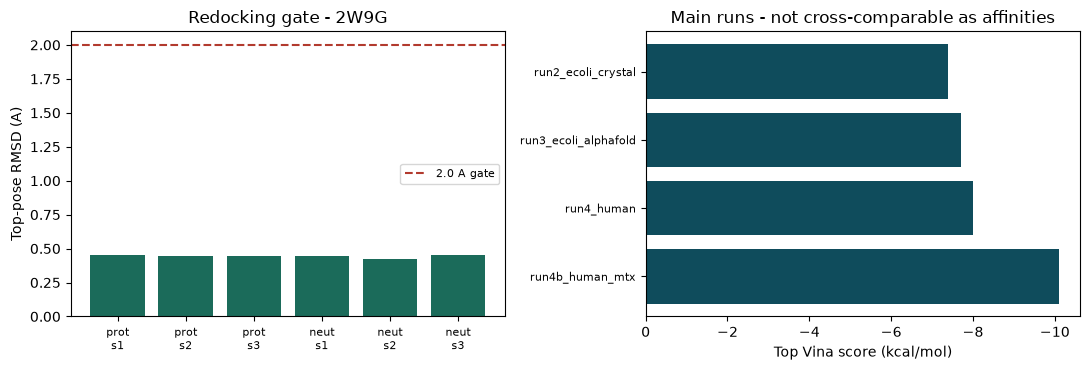

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

g = gate.copy()
colours = ["#1b6b5a" if p else "#b23a2e" for p in g.passes]
ax1.bar(range(len(g)), g.top_rmsd, color=colours)
ax1.axhline(GATE_A, ls="--", color="#b23a2e", label=f"{GATE_A} A gate")
ax1.set_xticks(range(len(g)))
ax1.set_xticklabels([f"{r.form[:4]}\ns{r.seed}" for r in g.itertuples()], fontsize=8)
ax1.set_ylabel("Top-pose RMSD (A)")
ax1.set_title("Redocking gate - 2W9G")
ax1.legend(fontsize=8)

m = main.sort_values("top_score")
ax2.barh(range(len(m)), m.top_score, color="#0f4c5c")
ax2.set_yticks(range(len(m)))
ax2.set_yticklabels(m.run, fontsize=8)
ax2.set_xlabel("Top Vina score (kcal/mol)")
ax2.set_title("Main runs - not cross-comparable as affinities")
ax2.invert_xaxis()

fig.tight_layout()
fig.savefig(D.FIGURES / "fig4_docking_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
gate.to_csv(D.RESULTS / "redock_gate.csv", index=False)
main.to_csv(D.RESULTS / "main_runs.csv", index=False)
sens.to_csv(D.RESULTS / "sensitivity.csv", index=False)
spread.to_csv(D.RESULTS / "sensitivity_spread.csv")

R_KCAL = 1.987e-3      # kcal / (mol K)
T_K = 310.0            # body temperature
RT = R_KCAL * T_K

ecoli = float(main.loc[main.run == "run2_ecoli_crystal", "top_score"].iloc[0])
human = float(main.loc[main.run == "run4_human", "top_score"].iloc[0])
af = float(main.loc[main.run == "run3_ecoli_alphafold", "top_score"].iloc[0])
mtx = float(main.loc[main.run == "run4b_human_mtx", "top_score"].iloc[0])
noise = float(spread["range"].max())

ddg = ecoli - human                      # negative => bacterial favoured
fold = np.exp(-ddg / RT)                 # predicted selectivity, bacterial over human
fold_per_kcal = np.exp(1.0 / RT)

# Trimethoprim's reported selectivity for bacterial over human DHFR spans
# roughly 10^3 - 10^5 fold depending on assay and organism.
lit_fold_low, lit_fold_high = 1e3, 1e5
need_low, need_high = RT * np.log(lit_fold_low), RT * np.log(lit_fold_high)

print(f"RT at {T_K:.0f} K                 : {RT:.3f} kcal/mol")
print(f"one log10 of selectivity     : {RT * np.log(10):.2f} kcal/mol")
print()
print(f"E. coli crystal              : {ecoli:7.2f} kcal/mol")
print(f"E. coli AlphaFold (apo)      : {af:7.2f} kcal/mol")
print(f"human 1U72                   : {human:7.2f} kcal/mol")
print(f"methotrexate -> human (ctrl) : {mtx:7.2f} kcal/mol")
print()
print(f"ddG (bacterial - human)      : {ddg:+.2f} kcal/mol")
print(f"  implied selectivity        : {fold:.1f}x "
      f"({'bacterial' if ddg < 0 else 'HUMAN'} favoured)")
print(f"largest seed-to-seed range   : {noise:.2f} kcal/mol")
print()
print(f"literature selectivity       : ~{lit_fold_low:.0e} - {lit_fold_high:.0e} fold")
print(f"  ddG that would require     : {need_low:.1f} to {need_high:.1f} kcal/mol")
print(f"  we observe                 : {abs(ddg):.2f} kcal/mol")
print()

if abs(ddg) < max(1.0, noise):
    print("VERDICT: the bacterial/human difference is within noise and roughly")
    print(f"{need_low / max(abs(ddg), 1e-9):.0f}x smaller than the "
          "smallest difference the pharmacology would require.")
    print("The docking does NOT reproduce trimethoprim's selectivity. Report the")
    print("number together with this caveat; do not call it a selectivity result.")
else:
    print("VERDICT: the difference exceeds the seed spread, but a Vina score is still")
    print("not an affinity. Report it as a ranking, not a measurement.")

print()
print(f"Positive control: methotrexate scores {mtx - human:+.2f} kcal/mol versus")
print("trimethoprim in the same human receptor, in the expected direction -")
print("evidence the pipeline is working and the null result above is real.")

RT at 310 K                 : 0.616 kcal/mol
one log10 of selectivity     : 1.42 kcal/mol

E. coli crystal              :   -7.38 kcal/mol
E. coli AlphaFold (apo)      :   -7.70 kcal/mol
human 1U72                   :   -7.99 kcal/mol
methotrexate -> human (ctrl) :  -10.11 kcal/mol

ddG (bacterial - human)      : +0.61 kcal/mol
  implied selectivity        : 0.4x (HUMAN favoured)
largest seed-to-seed range   : 0.06 kcal/mol

literature selectivity       : ~1e+03 - 1e+05 fold
  ddG that would require     : 4.3 to 7.1 kcal/mol
  we observe                 : 0.61 kcal/mol

VERDICT: the bacterial/human difference is within noise and roughly
7x smaller than the smallest difference the pharmacology would require.
The docking does NOT reproduce trimethoprim's selectivity. Report the
number together with this caveat; do not call it a selectivity result.

Positive control: methotrexate scores -2.12 kcal/mol versus
trimethoprim in the same human receptor, in the expected direction -
evidence the